# 実験6 (ex006): MNIST LeNet-5（大規模非凸モデル, $d=44,426$, 400ラウンド）比較

論文 Figure 4(c)・Figure 5(c)・Figure 6(b) の LeNet-5（400ラウンド）に対し、FedSSO および慣性付準ニュートン法 8 手法を 10 シードで比較します。
大規模フル逆ヘッセ行列 $H_k \in \mathbb{R}^{44,426 \times 44,426}$（約 7.89 GB）は `H.addmm_(U, V)` による完全 in-place rank-2 更新で追加 VRAM 消費ゼロのまま高速実行します。

In [1]:
import os
import torch
import pandas as pd
from model import verify_batched_lenet_equivalence
from utils import (
    DEFAULT_SEEDS, load_and_partition_mnist_2d, run_multiseed_lenet,
    plot_mnist_lenet_curves, plot_mnist_lenet_boxplot, plot_filtered_results,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'})")

使用デバイス: cuda (NVIDIA GeForce RTX 4080)


In [2]:
clients, packed_clients, X_train, y_train, X_test, y_test = load_and_partition_mnist_2d(
    data_dir="../datasets", num_clients=20, beta=0.1, train_ratio=0.75, seed=42, device=device
)
max_diff = verify_batched_lenet_equivalence(clients, packed_clients, tau=5, batch_size=100, lr=0.03, device=device)
print(f"MNIST 2D train={X_train.shape}, test={X_test.shape} | LeNet-5 並列SGD最大誤差: {max_diff:.3e}")

MNIST 2D train=torch.Size([52492, 1, 28, 28]), test=torch.Size([17508, 1, 28, 28]) | LeNet-5 並列SGD最大誤差: 8.645e-06


In [3]:
algo_configs = [
    {"name": "FedAvg",        "algo": "FedAvg",        "lr": 0.07},
    {"name": "FedSSO",        "algo": "FedSSO",        "lr": 0.03, "eta": 0.3},
    {"name": "FedSSO-NAQ",    "algo": "FedSSO-NAQ",    "lr": 0.03, "eta": 0.3, "mu": 0.25},
    {"name": "FedSSO-MoQ",    "algo": "FedSSO-MoQ",    "lr": 0.03, "eta": 0.3, "mu": 0.25},
    {"name": "FedSSO-AdaNAQ", "algo": "FedSSO-AdaNAQ", "lr": 0.03, "eta": 0.3, "max_mu": 0.30},
    {"name": "FedSSO-AdaMoQ", "algo": "FedSSO-AdaMoQ", "lr": 0.03, "eta": 0.3, "max_mu": 0.30},
    {"name": "FedSSO-LBFGS",  "algo": "FedSSO-LBFGS",  "lr": 0.03, "eta": 0.3, "m_size": 10},
    {"name": "FedSSO-LNAQ",   "algo": "FedSSO-LNAQ",   "lr": 0.03, "eta": 0.3, "max_mu": 0.30, "m_size": 10},
    {"name": "FedSSO-LMoQ",   "algo": "FedSSO-LMoQ",   "lr": 0.03, "eta": 0.3, "max_mu": 0.30, "m_size": 10},
    {"name": "FedSSO-MLNAQ",  "algo": "FedSSO-MLNAQ",  "lr": 0.03, "eta": 0.3, "max_mu": 0.30},
    {"name": "FedSSO-MLMoQ",  "algo": "FedSSO-MLMoQ",  "lr": 0.03, "eta": 0.3, "max_mu": 0.30},
]
summary_df, per_seed_df, curves_dict = run_multiseed_lenet(
    algo_configs=algo_configs, packed_clients=packed_clients,
    X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
    seeds=DEFAULT_SEEDS, rounds=400, tau=5, batch_size=100,
    save_log_dir="../datasets/ex006_mnist_lenet_logs",
    history_csv_path="../datasets/ex006_mnist_lenet_history.csv",
)
summary_df.to_csv("../datasets/ex006_mnist_lenet_summary.csv", index=False)
per_seed_df.to_csv("../datasets/ex006_mnist_lenet_per_seed.csv", index=False)
summary_df

,Algorithm,Comm_Per_Iter,Loss_Ave,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,MaxAcc_Ave,Clip_Ave,Reset_Ave,Server_Time_ms,Server_Mem_MB,Bytes@0.90,Reach@0.40,Iter@0.40,Comm@0.40,Reach@0.60,Iter@0.60,Comm@0.60,Reach@0.80,Iter@0.80,Comm@0.80,Reach@0.90,Iter@0.90,Comm@0.90,Reach@0.95,Iter@0.95,Comm@0.95,Reach@0.97,Iter@0.97,Comm@0.97
0,FedAvg,1.000,4.256817e-02,0.981643,0.981466,0.983836,0.978067,0.001550,0.982357,0.0,0.0,0.009451,0.169472,12759147,10/10,7.4,7.4,10/10,12.3,12.3,10/10,20.6,20.6,10/10,35.9,35.9,10/10,80.6,80.6,10/10,157.9,157.9
1,FedSSO,1.000,2.622713e-01,0.892398,0.986720,0.989319,0.099612,0.264816,0.987554,2.2,4.0,55.847209,7529.629440,9382771,10/10,10.9,10.9,10/10,13.5,13.5,10/10,18.4,18.4,10/10,26.4,26.4,10/10,39.8,39.8,10/10,61.7,61.7
2,FedSSO-NAQ,1.998,1.967232e-02,0.982705,0.982065,0.987891,0.976582,0.003320,0.984007,2.6,4.3,55.468376,7529.968384,24594234,10/10,18.1,35.2,10/10,22.0,43.0,10/10,26.4,51.8,10/10,35.1,69.2,10/10,52.3,103.6,10/10,84.1,167.2
3,FedSSO-MoQ,1.000,1.659885e+11,0.895751,0.983893,0.988234,0.098812,0.265661,0.906688,41.8,43.2,56.780392,7530.137856,11846933,9/10,20.2,20.2,9/10,22.7,22.7,9/10,26.9,26.9,9/10,33.3,33.3,9/10,45.2,45.2,9/10,65.3,65.3
4,FedSSO-AdaNAQ,1.998,2.692478e-01,0.808092,0.983436,0.987606,0.100000,0.351399,0.827073,62.0,43.6,52.517918,7529.968384,30031976,8/10,25.9,50.8,8/10,29.0,57.0,8/10,34.2,67.5,8/10,42.8,84.5,8/10,58.8,116.5,8/10,90.8,180.5
5,FedSSO-AdaMoQ,1.000,4.298275e-02,0.714493,0.973869,0.986006,0.100000,0.402337,0.752467,118.5,120.9,46.852413,7530.137856,11931554,7/10,17.6,17.6,7/10,20.3,20.3,7/10,24.7,24.7,7/10,33.6,33.6,7/10,51.4,51.4,7/10,78.4,78.4
6,FedSSO-LBFGS,1.000,4.984522e-02,0.979672,0.980580,0.983722,0.975897,0.002391,0.980672,62.0,2.6,1.574236,4.067322,13825371,10/10,17.2,17.2,10/10,20.5,20.5,10/10,26.1,26.1,10/10,38.9,38.9,10/10,66.6,66.6,10/10,131.2,131.2
7,FedSSO-LNAQ,1.998,6.119049e-02,0.976942,0.977353,0.978467,0.974297,0.001452,0.977467,130.3,2.3,1.751481,4.406265,27721824,10/10,17.5,34.0,10/10,22.1,43.2,10/10,27.6,54.2,10/10,39.5,78.0,10/10,68.9,136.8,10/10,129.2,257.4
8,FedSSO-LMoQ,1.000,6.657801e-02,0.974869,0.975840,0.980123,0.958305,0.005710,0.977799,107.5,2.9,1.494329,4.575737,15709034,10/10,18.9,18.9,10/10,22.9,22.9,10/10,28.8,28.8,10/10,44.2,44.2,10/10,77.6,77.6,10/10,142.6,142.6
9,FedSSO-MLNAQ,1.998,2.270928e-01,0.931574,0.930460,0.949166,0.910270,0.010094,0.932048,329.7,2.3,0.730924,1.355774,94254202,10/10,49.4,97.8,10/10,53.0,105.0,10/10,58.9,116.8,10/10,133.1,265.2,1/10,205.0,409.0,0/10,NaN,NaN


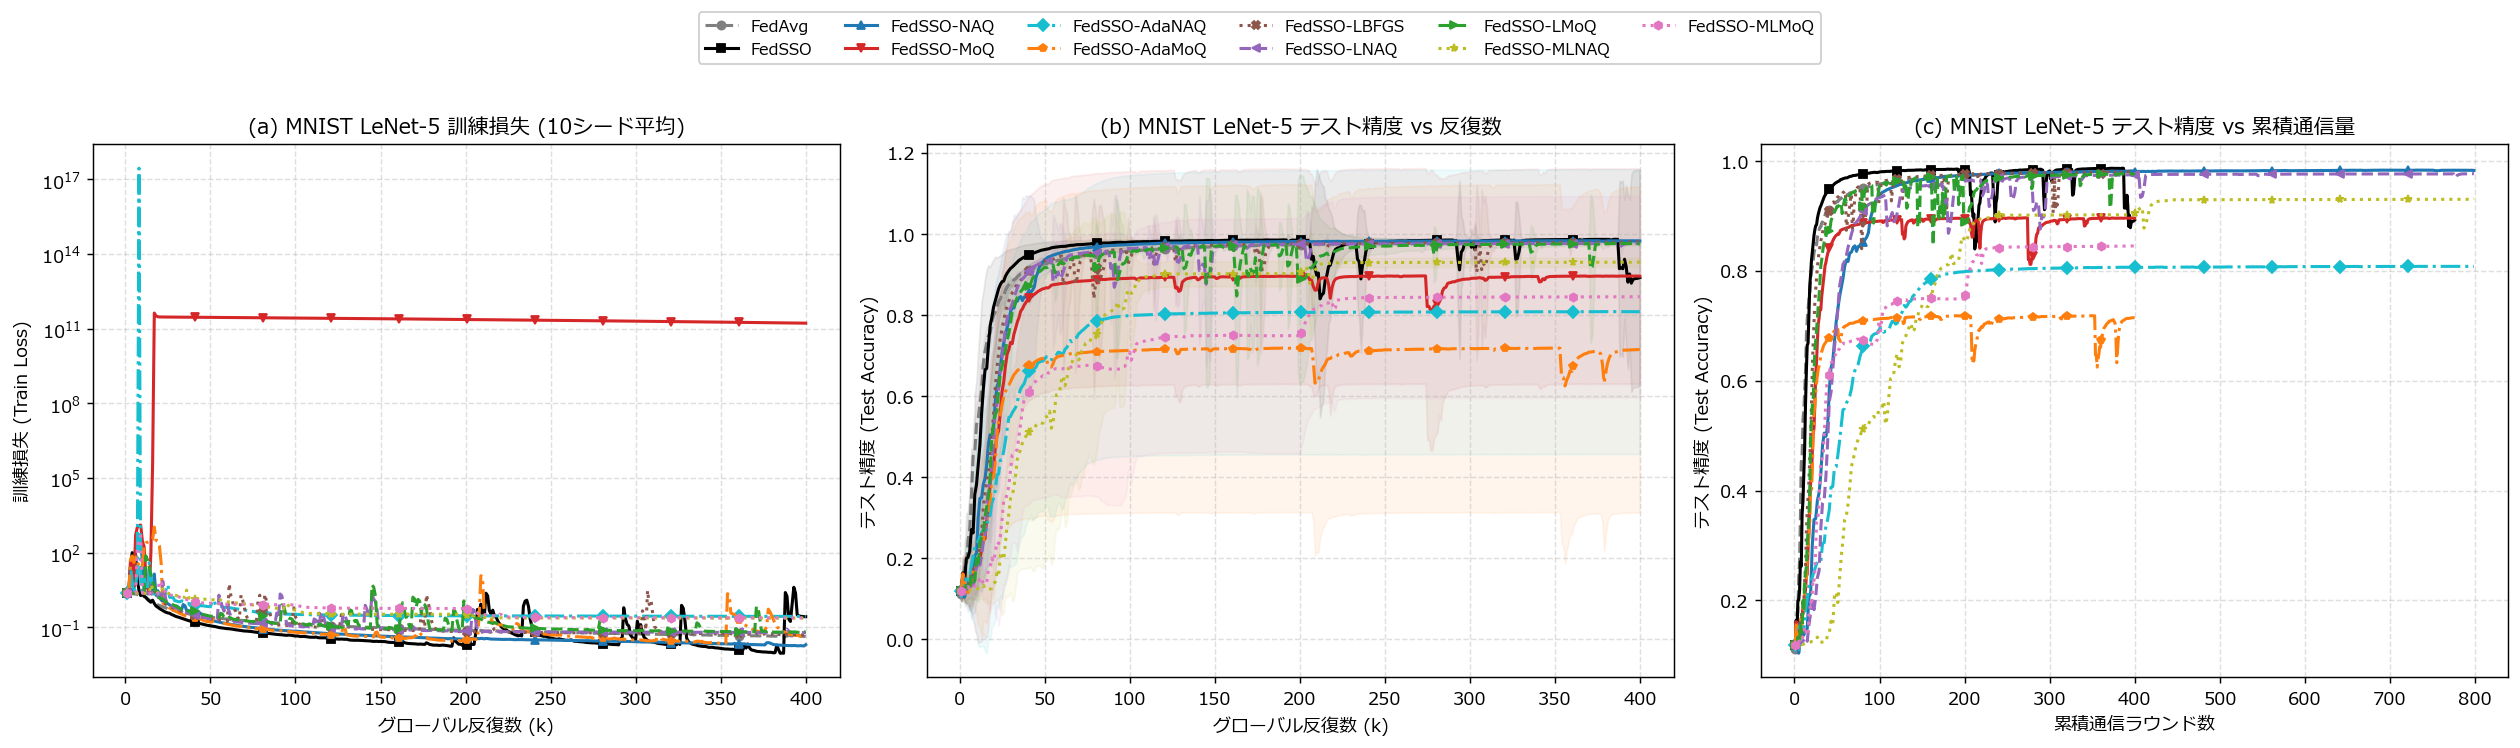

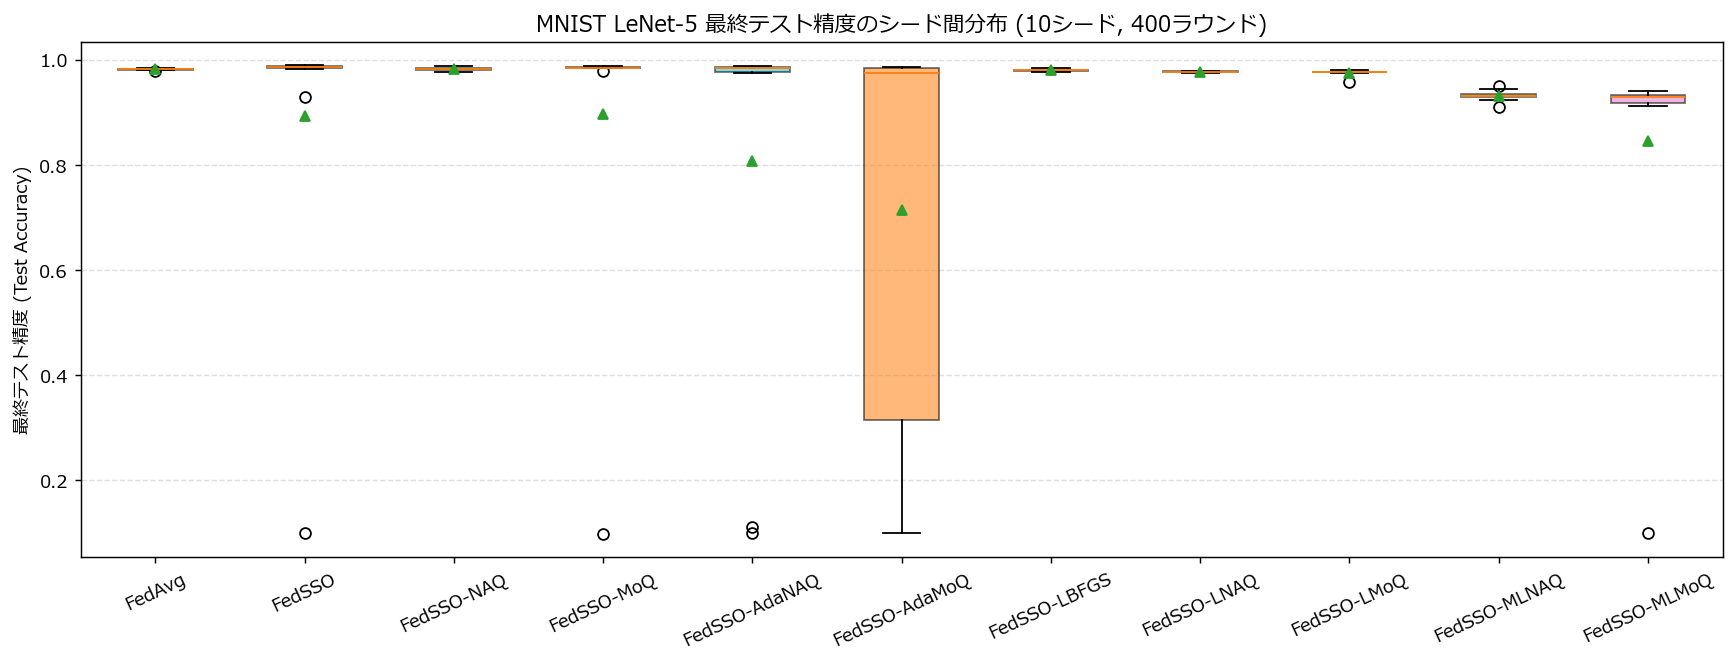

In [4]:
os.makedirs("../report/img", exist_ok=True)
plot_mnist_lenet_curves(curves_dict, save_path="../report/img/ex006_mnist_lenet_curves.png")
plot_mnist_lenet_boxplot(per_seed_df, save_path="../report/img/ex006_mnist_lenet_boxplot.png")

## 特定のシード値・アルゴリズムに絞ったグラフ表示

保存済みの全履歴 CSV（`../datasets/ex006_mnist_lenet_history.csv`）から任意のアルゴリズム・シード値だけを指定して再描画できます。 `SELECTED_SEEDS = None` のときは全シード平均のみを自動表示・出力します。

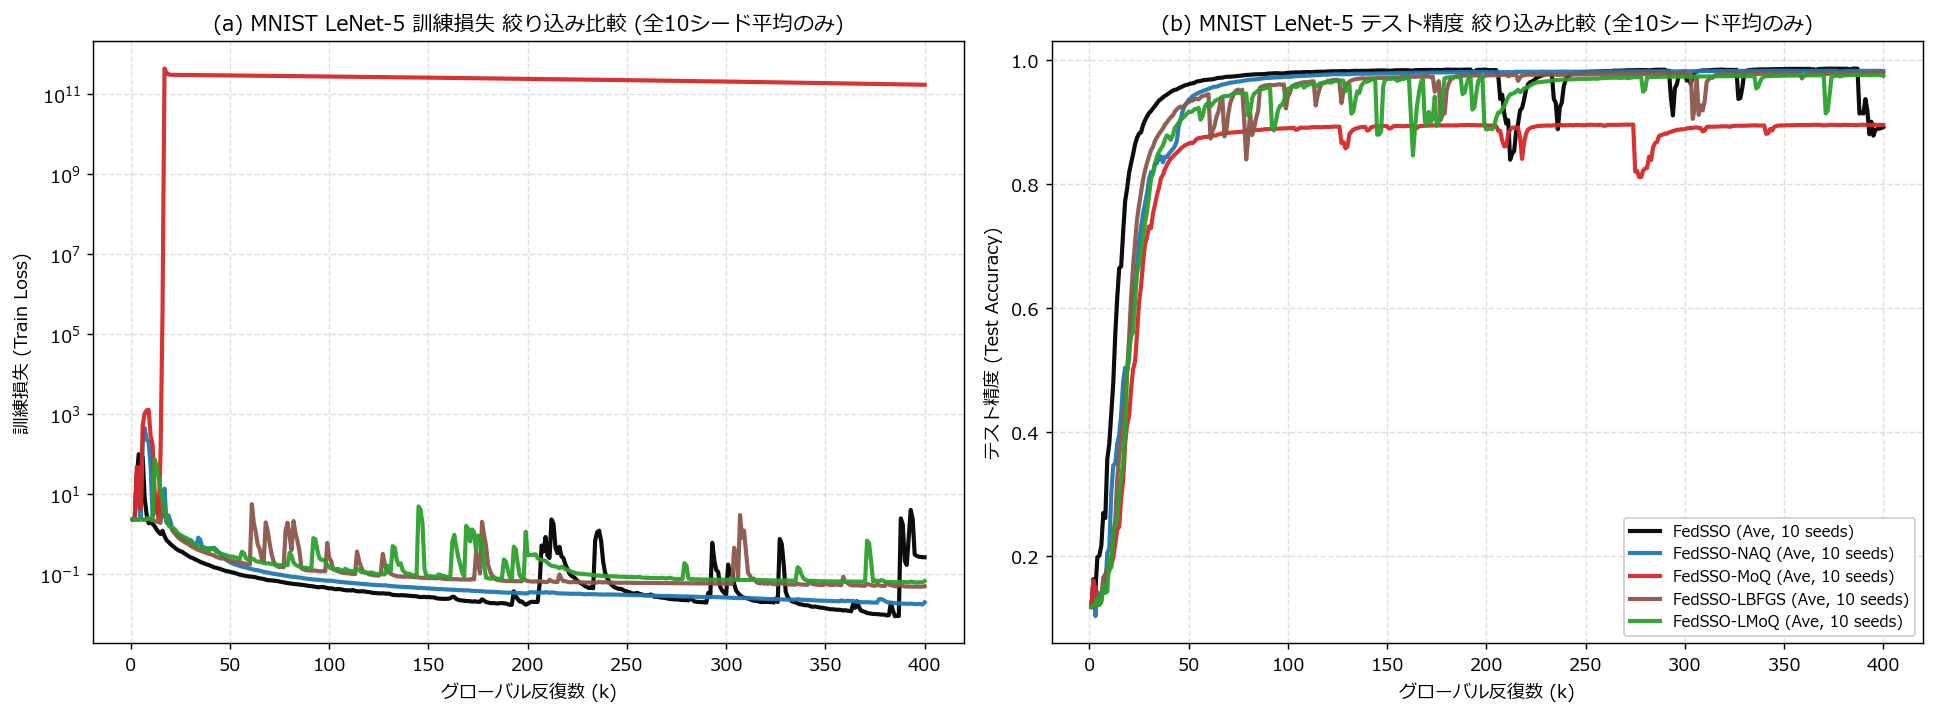

,Algorithm,Seeds,Round,Comm_Round,Train_Loss_Ave,Test_Acc_Ave
0,FedSSO,10,400,400.0,2.622713e-01,0.892398
1,FedSSO-NAQ,10,400,799.0,1.967232e-02,0.982705
2,FedSSO-MoQ,10,400,400.0,1.659885e+11,0.895751
3,FedSSO-LBFGS,10,400,400.0,4.984522e-02,0.979672
4,FedSSO-LMoQ,10,400,400.0,6.657801e-02,0.974869


In [5]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示
# 利用可能なアルゴリズム:
#   ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-AdaMoQ",
#    "FedSSO-LBFGS", "FedSSO-LNAQ", "FedSSO-LMoQ", "FedSSO-MLNAQ", "FedSSO-MLMoQ"]
#   None を指定すると全手法が対象になります
# 利用可能なシード値: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] (None で全シード対象)
SELECTED_ALGOS = ["FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-LBFGS", "FedSSO-LMoQ"]
SELECTED_SEEDS = None       # None で全10シード対象（例: [42, 46] で特定シードに絞り込み）
X_AXIS_MODE = "round"       # "round" (反復数) または "comm" (累積通信ラウンド数)
SHOW_MEAN_CURVE = True      # 複数シード指定時に平均太線を重ね描きするか
PLOT_MEAN_ONLY = "auto"     # "auto": SELECTED_SEEDS=None 時に平均線のみ描画 / True: 平均のみ / False: 個別シードも描画
TABLE_MEAN_ONLY = "auto"    # "auto": SELECTED_SEEDS=None 時に平均のみの行を出力 / True: 平均のみ / False: シード別に出力

filtered_df = plot_filtered_results(
    selected_algos=SELECTED_ALGOS,
    selected_seeds=SELECTED_SEEDS,
    history_csv_path="../datasets/ex006_mnist_lenet_history.csv",
    log_dir="../datasets/ex006_mnist_lenet_logs",
    x_axis=X_AXIS_MODE,
    show_mean=SHOW_MEAN_CURVE,
    plot_mean_only=PLOT_MEAN_ONLY,
    table_mean_only=TABLE_MEAN_ONLY,
)
filtered_df